In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt 
import seaborn as sns 
import copy, time
import os 
import numpy as np
import torchvision.utils as vu
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, random_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1337)

Loading latents 

In [2]:
latents = torch.load('./data/cifar_latents.pt')

In [3]:
latents.keys()

dict_keys(['latents', 'labels'])

In [4]:
x = latents['latents'].to(device)
y = latents['labels'].to(device)
x.shape, y.shape 

(torch.Size([50000, 4, 8, 8]), torch.Size([50000]))

Patchifying 

In [5]:
def unpatchify(x, p, c): 
    B, N, _ = x.shape 
    g = int(N **0.5)
    assert g*g ==N 
    x = x.reshape(B, g, g, c, p, p)
    x = x.permute(0, 3, 1, 4, 2, 5)
    x= x.reshape(B, c, g*p, g*p)
    return x 

### Position Embedding 

In [6]:
def sincos_1d(d, pos):
    i = torch.arange(d // 2, dtype=torch.float32, device = pos.device)
    omega = 1.0 / 10000 ** (2 * i / d)
    angles = pos.float()[:, None] * omega[None, :]
    return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

def sincos_pos_embed(D, g):
    table = sincos_1d(D // 2, torch.arange(g))
    rows = table.repeat_interleave(g, dim=0)
    cols = table.repeat(g, 1)
    return torch.cat([rows, cols], dim=1)

       row information | column information
A →       R0           |       C0
B →       R0           |       C1
C →       R0           |       C2

D →       R1           |       C0
E →       R1           |       C1
F →       R1           |       C2

G →       R2           |       C0
H →       R2           |       C1
I →       R2           |       C2

In [7]:
torch.manual_seed(1337)
class Patchify(nn.Module):
    
    def __init__(self, in_channels, D, p):
        super().__init__()
        
        self.in_channels = in_channels
        self.D = D # Embedding dimension 
        self.p = p 
        self.layer1=  nn.Conv2d(in_channels, D, kernel_size = p, stride = p) 
        
    def forward(self, x):
        result = self.layer1(x)
        result = result.flatten(2).transpose(1,2) # B, C, H * W --> B, H*W, C
        return result 
    

In [8]:
torch.manual_seed(1337)

class TimestepEmbedder(nn.Module):

    def __init__(self, D):
        super().__init__()
        self.D = D
        self.mlp = nn.Sequential(nn.Linear(D, D), nn.SiLU(), nn.Linear(D, D))  
        
    def forward(self, t):
        return self.mlp(sincos_1d(self.D, t))
    

### AdaLN zero 

In [9]:
torch.manual_seed(1337)

class AdaLNzero(nn.Module):
    
    def __init__(self, hid_dim, emb_dim):
        super().__init__()
        
        self.hid_dim = hid_dim 
        self.emb_dim = emb_dim 
        
        self.adal = nn.Sequential(
            nn.SiLU(),
            nn.Linear(emb_dim , hid_dim * 6  ),
        )
        self.initialize_weight()
    
    def forward(self, c):
        # shift_msa, scale_msa, alpha_msa, shift_mlp, scale_mlp, alpha_mlp 
        
        result = self.adal(c).chunk(6, dim =1)
        return [r.unsqueeze(1) for r in result]
        
    def initialize_weight(self):
        nn.init.constant_(self.adal[-1].weight, 0)
        nn.init.constant_(self.adal[-1].bias, 0)

## AdalN

In [10]:
torch.manual_seed(1337)

class AdaLN(nn.Module):
    
    def __init__(self, hid_dim, emb_dim):
        super().__init__()
        
        self.hid_dim = hid_dim 
        self.emb_dim = emb_dim 
        
        self.adal = nn.Sequential(
            nn.SiLU(),  # sigmoid linear unit (x * sig(x))
            nn.Linear(emb_dim , hid_dim *4),
        )    
    def forward(self, c):
        # shift_msa, scale_msa, alpha_msa, shift_mlp, scale_mlp, alpha_mlp 
        
        result = self.adal(c).chunk(4, dim =1)
        return [r.unsqueeze(1) for r in result]
    

In [ ]:
torch.manual_seed(1337)
class DiTBlockAdalN(nn.Module):

    def __init__(self, D, num_heads ):
        super().__init__()
        
        self.norm1 = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.norm2 = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(D, num_heads, batch_first = True)
        self.mlp = nn.Sequential(
            nn.Linear(D, 4*D), 
            nn.GELU(), # Gaussian error linear unit
            nn.Linear(4*D, D)
            )
        self.adaLn = AdaLN(D, D)
        
    def forward(self, x, c):
        shift_msa, scale_msa, shift_mlp, scale_mlp = self.adaLn(c)

        # Attention sub-block
        h = self.norm1(x) * (1 + scale_msa) + shift_msa
        out = self.attn(h, h, h)[0]
        x = x + out

        # MLP sub-block
        h = self.norm2(x) * (1 + scale_mlp) + shift_mlp
        out = self.mlp(h)
        x = x + out

        return x
            
        

### DiT class 

In [12]:
torch.manual_seed(1337)

class FinalLayer(nn.Module):
    
    def __init__(self, D, p, out_channels):
        super().__init__()
        
        self.norm = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.ada = nn.Sequential(
            nn.SiLU(),
            nn.Linear(D, 2 * D)
            )
        self.linear = nn.Linear(D, p * p * out_channels)
        for layer in (self.ada[-1], self.linear):
            nn.init.constant_(layer.weight, 0)
            nn.init.constant_(layer.bias, 0)

    def forward(self, x, c):
        shift, scale = self.ada(c).chunk(2, dim=1)
        x = self.norm(x) * (1 + scale.unsqueeze(1)) + shift.unsqueeze(1)
        return self.linear(x)


class DiT(nn.Module):
    
    def __init__(self, input_size, in_channels, D, p, depth, num_heads, num_classes=10,conditioning="adalnzero"):
        super().__init__()
        
        assert input_size % p == 0
        self.p = p
        self.out_channels = in_channels
        g = input_size // p

        self.patch = Patchify(in_channels=in_channels, D=D, p=p)
        self.t_embed = TimestepEmbedder(D)
        self.y_embed = nn.Embedding(num_classes, D)
        self.register_buffer("pos_embed", sincos_pos_embed(D, g).unsqueeze(0))
        if conditioning =='adalnzero':
            self.blocks = nn.ModuleList([DiTBlock(D, num_heads) for _ in range(depth)])
        else :
            self.blocks = nn.ModuleList([DiTBlockAdalN(D, num_heads) for _ in range(depth)])
            
        self.final = FinalLayer(D, p, in_channels)

    def forward(self, x, t, y):
        # Patchify + pos embedding 
        x = self.patch(x) + self.pos_embed
        
        #time embedding + label embedding 
        c = self.t_embed(t) + self.y_embed(y)
        
        # Dit Block
        for block in self.blocks:
            x = block(x, c)
            
        # Final layer 
        x = self.final(x, c)
        
        return unpatchify(x, self.p, self.out_channels)

###  dit block 


In [13]:
torch.manual_seed(1337)

class DiTBlock(nn.Module):
    
    def __init__(self, D, num_heads ):
        super().__init__()
        
        self.norm1 = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.norm2 = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(D, num_heads, batch_first = True)
        self.mlp = nn.Sequential(
            nn.Linear(D, 4*D), 
            nn.GELU(), # Gaussian error linear unit
            nn.Linear(4*D, D)
            )
        self.adaLN = AdaLNzero(D, D)
        
    def forward(self, x, c):
        shift_msa, scale_msa, alpha_msa, shift_mlp, scale_mlp, alpha_mlp = self.adaLN(c)
        
        # Msa sub-block
        h = self.norm1(x) * (1 + scale_msa) + shift_msa
        out = self.attn(h, h, h)[0]
        # residual add
        x1 = x + alpha_msa * out
        
        # Mlp sub-block
        h1 = self.norm2(x1) * (1 + scale_mlp) + shift_mlp 
        out1 = self.mlp (h1)
        x2 = x1 + alpha_mlp * out1
        return x2 
        
        

In [14]:
# B, N, p*p*C--> B, C, H, W ,  h*w == N 

In [15]:
torch.manual_seed(1337)
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1- betas 
alpha_bar = torch.cumprod(alphas, dim = 0)

def q_sample(x0, t, eps):
    ab = alpha_bar.to(x0.device)[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1- ab).sqrt() * eps


### Training 

In [16]:
B, C, H, W = x.shape
x.shape 

torch.Size([50000, 4, 8, 8])

In [17]:
len(latents['latents']), len(x), x.device

(50000, 50000, device(type='cuda', index=0))

The DiT paper's named sizes are  
 `S (D=384, 12 layers, 6 heads)`,   
 `B (768, 12, 12)`,  
 `L (1024, 24, 16)` and   
 `XL (1152, 28, 16)`.

In [ ]:
"""  adaln : depth  : 6 """
torch.manual_seed(1337)
dit = DiT(input_size= H, in_channels = C, p = 2, D= 192, depth = 6, num_heads = 3,num_classes = 10 , conditioning='adaln').to(device)
opt = torch.optim.AdamW(dit.parameters(), lr=1e-4, weight_decay=0)

ema = copy.deepcopy(dit).eval()
for p in ema.parameters():
    p.requires_grad_(False)

batch_size = 128
steps = 100000
all_loss = []
start = time.time()

for step in range(steps):
    idx = torch.randint(0, len(x), (batch_size,), device=device)
    x0 = x[idx]
    y0 = y[idx]
    t = torch.randint(0, T, (batch_size,), device=device)
    noise = torch.randn_like(x0) # Gaussian noise 
    # Clean latent + noise
    noisy_latent = q_sample(x0, t, eps = noise)
    predicted_noise = dit(noisy_latent, t, y0)
    loss = F.mse_loss(predicted_noise, noise) 
    opt.zero_grad()
    loss.backward()
    opt.step()
    
    with torch.no_grad():
        for ep, dp in zip(ema.parameters(), dit.parameters()):
            ep.lerp_(dp, 0.001)
            # ep += 0.001( dp - ep)
            
    if not (step+1) % 100 :
        all_loss.append(loss.item())
        print(step)

torch.save({"config": dict(input_size=H, in_channels=C, p=2, D=192, depth=6, num_heads=3),    "conditioning": "adaln", "model": dit.state_dict(), "ema": ema.state_dict(), "loss": all_loss, "step": steps, "seed": 1337}, './data/dit_depth6_100k_adaln.pt')

In [ ]:
""" Adalnzero, depth 6 """
torch.manual_seed(1337)
dit = DiT(input_size= H, in_channels = C, p = 2, D= 192, depth = 6, num_heads = 3,num_classes = 10 ).to(device)
opt = torch.optim.AdamW(dit.parameters(), lr=1e-4, weight_decay=0)

ema = copy.deepcopy(dit).eval()
for p in ema.parameters():
    p.requires_grad_(False)

batch_size = 128
steps = 100000
all_loss = []
start = time.time()

for step in range(steps):
    idx = torch.randint(0, len(x), (batch_size,), device=device)
    x0 = x[idx]
    y0 = y[idx]
    # Time step 
    t = torch.randint(0, T, (batch_size,), device=device)
    noise = torch.randn_like(x0) 
    noisy_latent = q_sample(x0, t, eps = noise)
    predicted_noise = dit(noisy_latent, t, y0)
    loss = F.mse_loss(predicted_noise, noise) 
    opt.zero_grad()
    loss.backward()
    opt.step()
    
    with torch.no_grad():
        for ep, dp in zip(ema.parameters(), dit.parameters()):
            ep.lerp_(dp, 0.001)
            
    if not (step+1) % 100 :
        all_loss.append(loss.item())
        print(step)

torch.save({"config": dict(input_size=H, in_channels=C, p=2, D=192, depth=6, num_heads=3),    "conditioning": "adalnzero", "model": dit.state_dict(), "ema": ema.state_dict(), "loss": all_loss, "step": steps, "seed": 1337}, "./data/dit_depth6_100k_adalnzero.pt")




In [ ]:
""" Adalnzero, depth 4"""
torch.manual_seed(1337)
dit = DiT(input_size= H, in_channels = C, p = 2, D= 192, depth = 4, num_heads = 3,num_classes = 10 ).to(device)
opt = torch.optim.AdamW(dit.parameters(), lr=1e-4, weight_decay=0)

ema = copy.deepcopy(dit).eval()
for p in ema.parameters():
    p.requires_grad_(False)

batch_size = 128
steps = 100000
all_loss = []
start = time.time()

for step in range(steps):
    idx = torch.randint(0, len(x), (batch_size,), device=device)
    x0 = x[idx]
    y0 = y[idx]
    t = torch.randint(0, T, (batch_size,), device=device)
    noise = torch.randn_like(x0) 
    noisy_latent = q_sample(x0, t, eps = noise)
    predicted_noise = dit(noisy_latent, t, y0)
    loss = F.mse_loss(predicted_noise, noise) 
    opt.zero_grad()
    loss.backward()
    opt.step()
    
    with torch.no_grad():
        for ep, dp in zip(ema.parameters(), dit.parameters()):
            ep.lerp_(dp, 0.001)
            
    if not (step+1) % 100 :
        all_loss.append(loss.item())
        print(step)

torch.save({"config": dict(input_size=H, in_channels=C, p=2, D=192, depth=6, num_heads=3),"conditioning": "adalnzero", "model": dit.state_dict(), "ema": ema.state_dict(), "loss": all_loss, "step": steps, "seed": 1337}, "./data/dit_depth4_100k_adalnzero.pt")




In [21]:
from diffusers import AutoencoderKL 
VAE = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-ema').to(device).eval()  

/home/vaibhav/miniconda3/envs/pytorch/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Random noise → DiT predicts noise → reverse-diffusion loop → final latent → VAE decoder → generated image.

In [ ]:
@torch.no_grad()
def get_latent(model, y):
    b = betas.to(device) #noise variance added at each forward step
    a = alphas.to(device) # signal-retention factor at each step
    ab = alpha_bar.to(device)
    x = torch.randn(len(y), 4, 8, 8, device=device)
    for t in range(T - 1, -1, -1):
        tt = torch.full((len(y),), t, device=device, dtype=torch.long)
        eps_pred = model(x, tt, y)
        
        # Next clean latent
        x = (x - b[t] / (1 - ab[t]).sqrt() * eps_pred) / a[t].sqrt()
        if t >0:
            x += b[t].sqrt() * torch.randn_like(x)
    return x

In [23]:
def show(t, nrow=8):
    g = vu.make_grid(((t.clamp(-1, 1) + 1) / 2).cpu(), nrow=nrow)
    plt.figure(figsize=(12,12))
    plt.imshow(g.permute(1, 2, 0))
    plt.axis("off")
    plt.show()

In [24]:
test1  = torch.load('./data/dit_depth4_100k_adalnzero.pt',map_location = device , weights_only = False )
test2  = torch.load('./data/dit_depth6_100k_adalnzero.pt',map_location = device , weights_only = False )
test3  = torch.load('./data/dit_depth6_100k_adaln.pt',map_location = device , weights_only = False )

In [25]:
test1['config'], test2['config'], test3['config']

({'input_size': 8,
  'in_channels': 4,
  'p': 2,
  'D': 192,
  'depth': 4,
  'num_heads': 3},
 {'input_size': 8,
  'in_channels': 4,
  'p': 2,
  'D': 192,
  'depth': 6,
  'num_heads': 3},
 {'input_size': 8,
  'in_channels': 4,
  'p': 2,
  'D': 192,
  'depth': 6,
  'num_heads': 3})

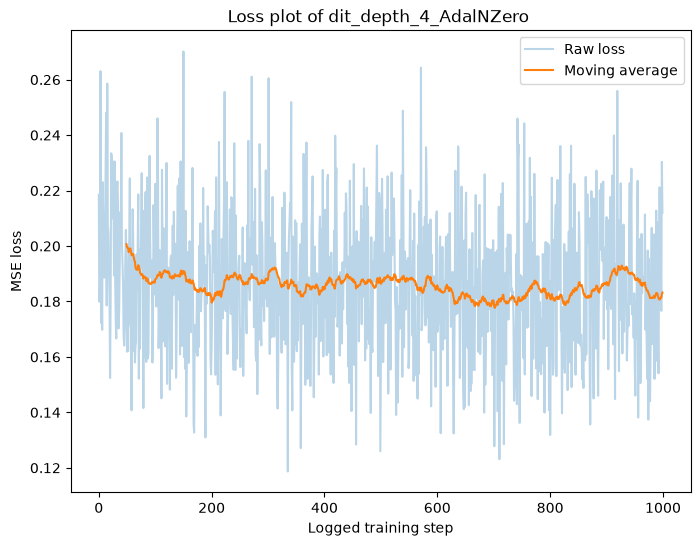

In [26]:
loss = np.asarray(test1['loss'])
window = 50

smoothed = np.convolve(
    test1['loss'],
    np.ones(window) / window,
    mode="valid"
)
plt.figure(figsize=(8, 6))
plt.plot(loss, alpha=0.30, label="Raw loss")
plt.plot(
    np.arange(window -1, len(test1['loss'])),
    smoothed,
    label="Moving average"
)
plt.title('Loss plot of dit_depth_4_AdalNZero ')
plt.xlabel("Logged training step")
plt.ylabel("MSE loss")
plt.legend()
plt.show()

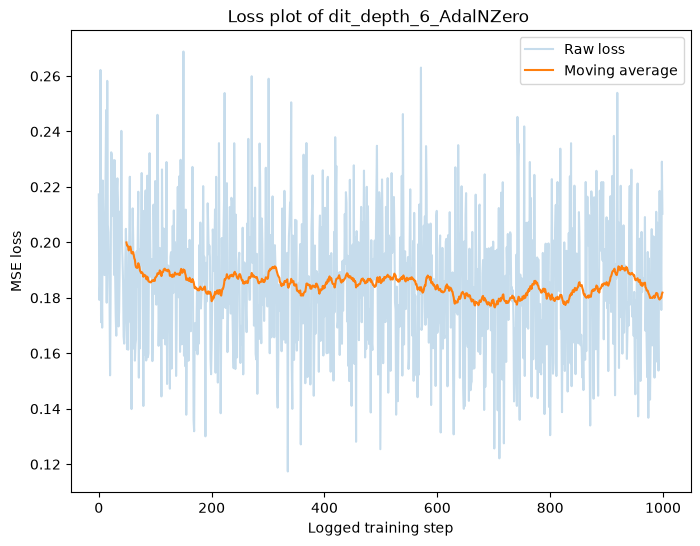

In [27]:
loss = np.asarray(test2['loss'])
smoothed = np.convolve(
    test2['loss'],
    np.ones(window) / window,
    mode="valid"
)
plt.figure(figsize=(8, 6))
plt.plot(loss, alpha=0.25, label="Raw loss")
plt.plot(
    np.arange(window - 1, len(test2['loss'])),
    smoothed,
    label="Moving average"
)
plt.title('Loss plot of dit_depth_6_AdalNZero ')
plt.xlabel("Logged training step")
plt.ylabel("MSE loss")
plt.legend()
plt.show()

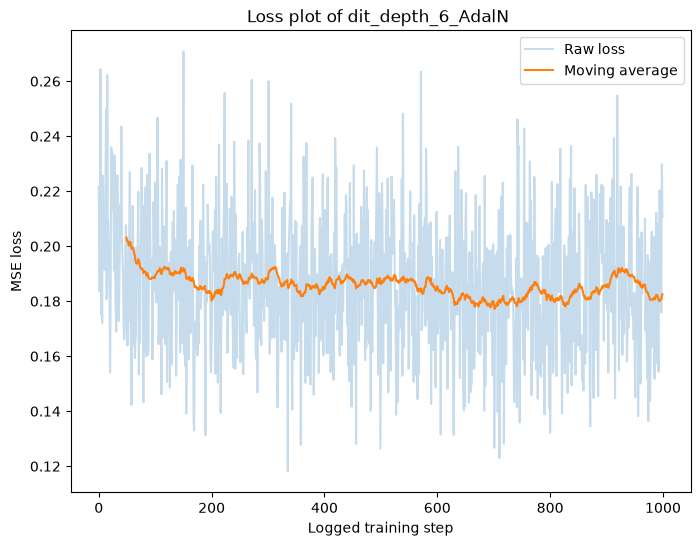

In [28]:
loss = np.asarray(test3['loss']) 
smoothed = np.convolve(
    test3['loss'],
    np.ones(window) / window,
    mode="valid"
)
plt.figure(figsize=(8, 6))
plt.plot(loss, alpha=0.25, label="Raw loss")
plt.plot(
    np.arange(window - 1, len(test3['loss'])),
    smoothed,
    label="Moving average"
)
plt.title('Loss plot of dit_depth_6_AdalN ')
plt.xlabel("Logged training step")
plt.ylabel("MSE loss")
plt.legend()
plt.show()

### Evaluation 

In [30]:
dataset = TensorDataset(x.cpu(), y.cpu())

n_eval = int(0.1 * len(dataset))
n_train = len(dataset) - n_eval

train_set, eval_set = random_split(
    dataset,
    [n_train, n_eval],
    generator=torch.Generator().manual_seed(1337)
)

eval_loader = DataLoader(
    eval_set,
    batch_size=128,
    shuffle=False,
    drop_last=False
)

In [31]:
eval_batches = []

g = torch.Generator(device=device).manual_seed(1337)

for x0, y0 in eval_loader:
    x0 = x0.to(device)
    y0 = y0.to(device)

    t = torch.randint(0, T, (len(x0),), device=device, generator=g)
    noise = torch.randn(x0.shape, device=device, dtype=x0.dtype, generator=g)

    eval_batches.append((x0, y0, t, noise))

depth6_adalnzero: MSE = 0.180600


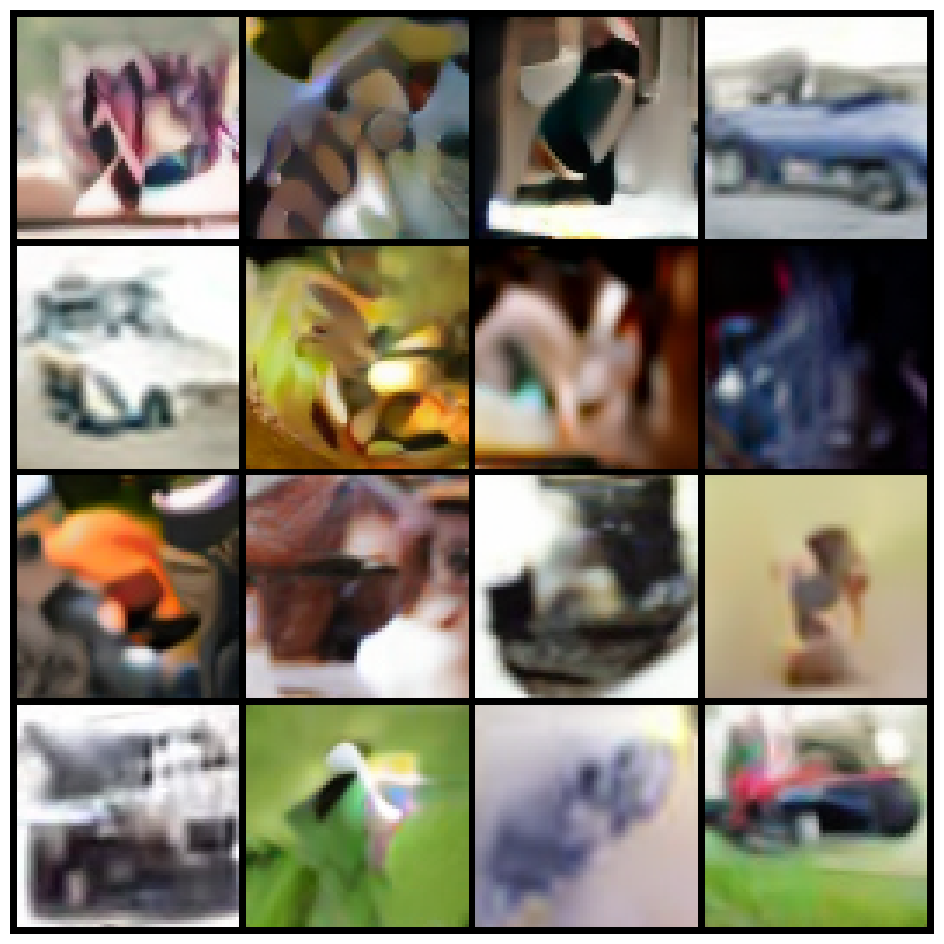

depth6_adaln: MSE = 0.181100


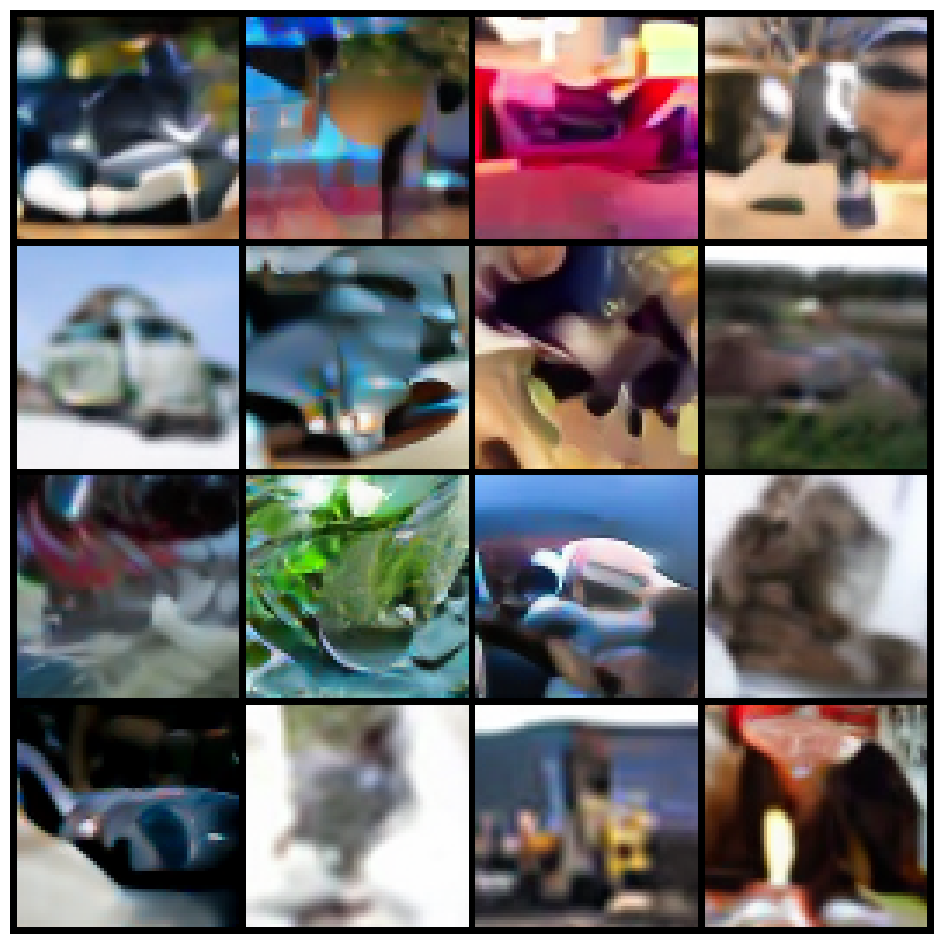

depth4_adalnzero: MSE = 0.182100


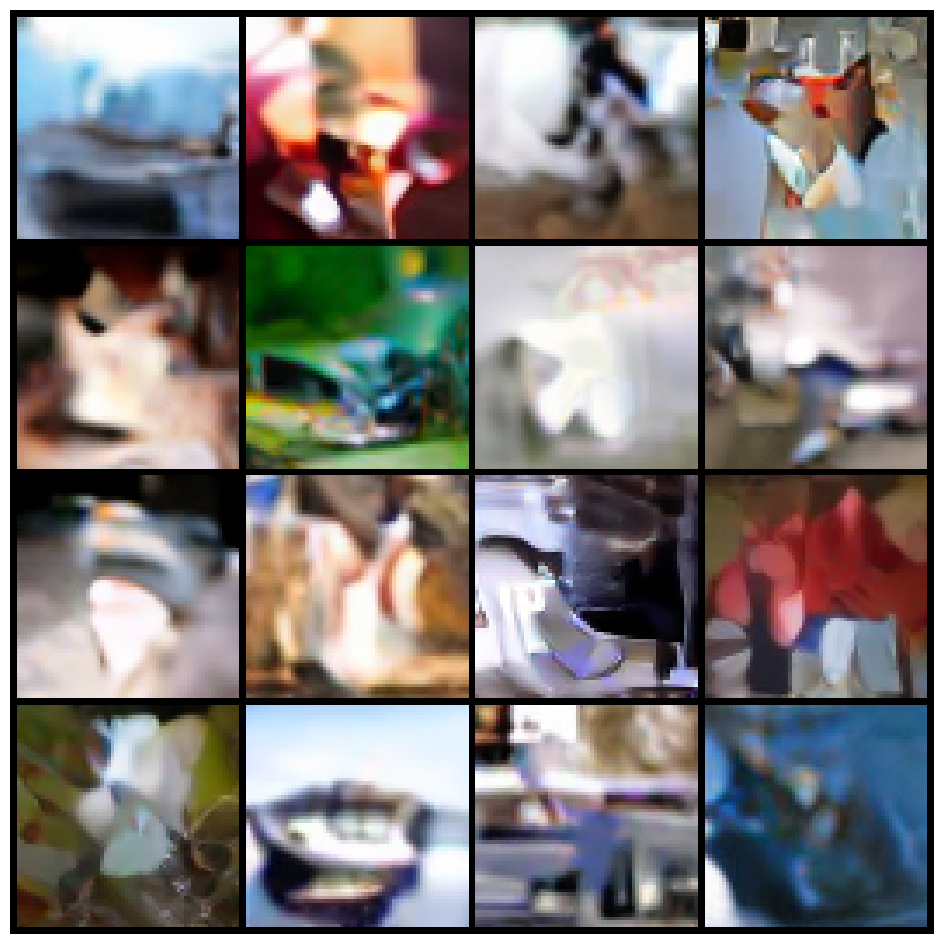

In [33]:
checkpoints = {
    "depth6_adalnzero": "./data/dit_depth6_100k_adalnzero.pt",
    "depth6_adaln": "./data/dit_depth6_100k_adaln.pt",
    "depth4_adalnzero": "./data/dit_depth4_100k_adalnzero.pt",
}

results = {}
parameters = {}

for name, path in checkpoints.items():
    ckpt = torch.load(path, map_location=device, weights_only=False)

    model = DiT(
        input_size=ckpt["config"]["input_size"],
        in_channels=ckpt["config"]["in_channels"],
        p=ckpt["config"]["p"],
        D=ckpt["config"]["D"],
        depth=ckpt["config"]["depth"],
        num_heads=ckpt["config"]["num_heads"],
        num_classes=10,
        conditioning= ckpt["conditioning"]
    ).to(device)
    
    model.load_state_dict(ckpt["ema"])
    model.eval()
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    parameters[name]= round(trainable/1e+6,3)
    
    
    total_squared_error = 0.0
    total_elements = 0

    with torch.no_grad():
        for x0, y0, t, noise in eval_batches:
            noisy = q_sample(x0, t, eps=noise)
            pred = model(noisy, t, y0)

            total_squared_error += F.mse_loss(
                pred, noise, reduction="sum"
            ).item()
            total_elements += noise.numel()

    results[name] = round(total_squared_error / total_elements, 4)

    print(f"{name}: MSE = {results[name]:.6f}")
    
    yt = torch.randint(0, 10,(16,), device=device)
    latent = get_latent(model, yt)
    with torch.no_grad():
        img = VAE.decode(latent / 0.18215).sample
    show(img,4)
    del model

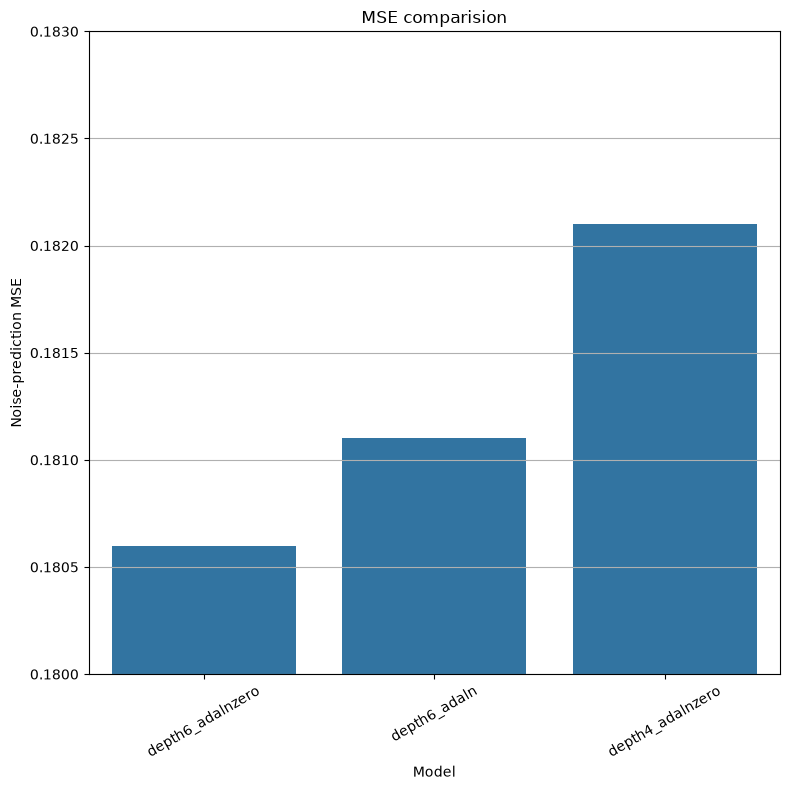

In [34]:
plt.figure(figsize=(8, 8))
sns.barplot(x = results.keys(),  y=results.values())
plt.ylim(0.18,0.183)
plt.grid(True, axis= 'y')
plt.ylabel("Noise-prediction MSE")
plt.xlabel("Model")
plt.title("MSE comparision")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd 

In [36]:
results, parameters

({'depth6_adalnzero': 0.1806,
  'depth6_adaln': 0.1811,
  'depth4_adalnzero': 0.1821},
 {'depth6_adalnzero': 4.155, 'depth6_adaln': 3.71, 'depth4_adalnzero': 2.822})

In [42]:
df = pd.DataFrame(parameters,index = ['Total parameters(M)']).T
final_result = pd.concat([df, pd.DataFrame(results, index =['MSE']).T],axis =1 )
final_result

,Total parameters(M),MSE
depth6_adalnzero,4.155,0.1806
depth6_adaln,3.710,0.1811
depth4_adalnzero,2.822,0.1821
